# Laboratorium 5 – warstwy splotowe


## Import bibliotek

In [1]:
import os
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Zdjęcie wejściowe

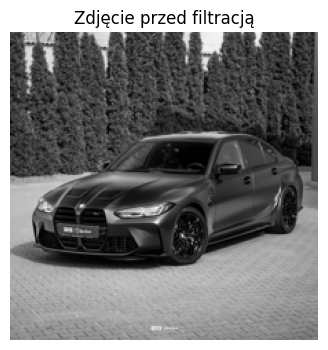

In [2]:
photo = "BMW-M3-Mat-5-of-10-1024x1024.jpg"
url = "https://raw.githubusercontent.com/Mateusz19W/lab1-mlp-fashionmnist/main/BMW-M3-Mat-5-of-10-1024x1024.jpg"

if not os.path.exists(photo):
    urllib.request.urlretrieve(url, photo)

pil = Image.open(photo).convert("L").resize((224, 224))
gray = torch.from_numpy(np.array(pil)).float().unsqueeze(0).unsqueeze(0) / 255.0

plt.figure(figsize=(4, 4))
plt.imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
plt.title("Zdjęcie przed filtracją")
plt.axis("off")
plt.savefig("01_zdjecie.png", dpi=160, bbox_inches="tight")
plt.show()

## 1. Ręczne jądra

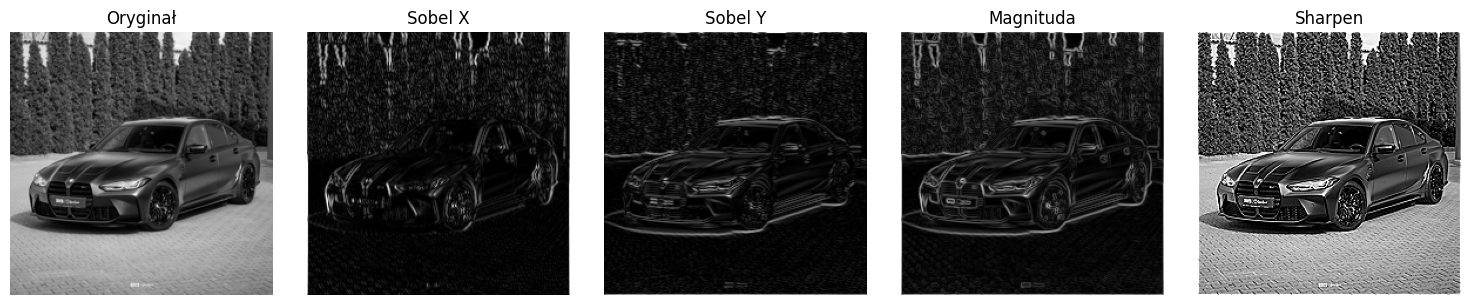

In [3]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(1, 1, *np.array(t).shape)


sobel_x = kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = sobel_x.transpose(-2, -1)
sharpen = kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
magnitude = (gx.square() + gy.square()).sqrt()

results = {
    "Oryginał": gray,
    "Sobel X": gx.abs(),
    "Sobel Y": gy.abs(),
    "Magnituda": magnitude,
    "Sharpen": F.conv2d(gray, sharpen, padding=1).clamp(0, 1),
}
fig, axes = plt.subplots(1, len(results), figsize=(15, 3))
for ax, (name, out) in zip(axes, results.items()):
    ax.imshow(out[0, 0].detach(), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.savefig("02_jadra_reczne.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Wymiary wyjścia

In [4]:
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1


IN = 32
configs = [
    dict(k=3, s=1, p=1, d=1),
    dict(k=3, s=2, p=1, d=1),
    dict(k=5, s=1, p=2, d=1),
    dict(k=3, s=1, p=2, d=2),
    dict(k=7, s=2, p=3, d=1),
]

x = torch.randn(1, 3, IN, IN)
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'wzór':>5} {'Conv2d':>7}")
for c in configs:
    conv = nn.Conv2d(3, 8, kernel_size=c['k'], stride=c['s'],
                     padding=c['p'], dilation=c['d'])
    formula = out_dim(IN, **c)
    real = conv(x).shape[-1]
    assert formula == real
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | "
          f"{formula:>5} {real:>7}")

 k  s  p  d |  wzór  Conv2d
 3  1  1  1 |    32      32
 3  2  1  1 |    16      16
 5  1  2  1 |    32      32
 3  1  2  2 |    32      32
 7  2  3  1 |    16      16


## 3. Wpływ stride, padding i dilation

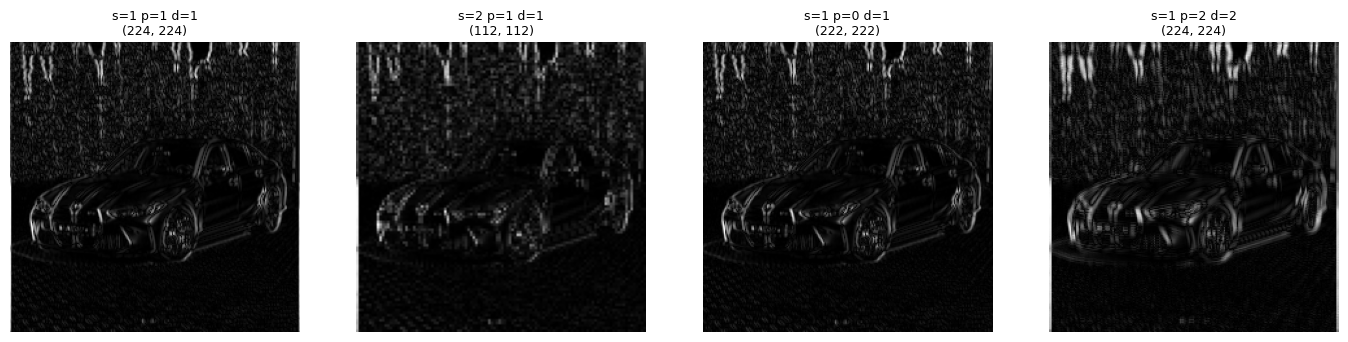

In [5]:
settings = [
    dict(stride=1, padding=1, dilation=1),
    dict(stride=2, padding=1, dilation=1),
    dict(stride=1, padding=0, dilation=1),
    dict(stride=1, padding=2, dilation=2),
]

fig, axes = plt.subplots(1, len(settings), figsize=(14, 3.4))
for ax, s in zip(axes, settings):
    out = F.conv2d(gray, sobel_x, **s)
    ax.imshow(out[0, 0].abs().detach(), cmap="gray")
    ax.set_title(f"s={s['stride']} p={s['padding']} d={s['dilation']}\n"
                 f"{tuple(out.shape[-2:])}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("03_parametry.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Mapy cech pretrenowanego ResNet-18

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 106MB/s]


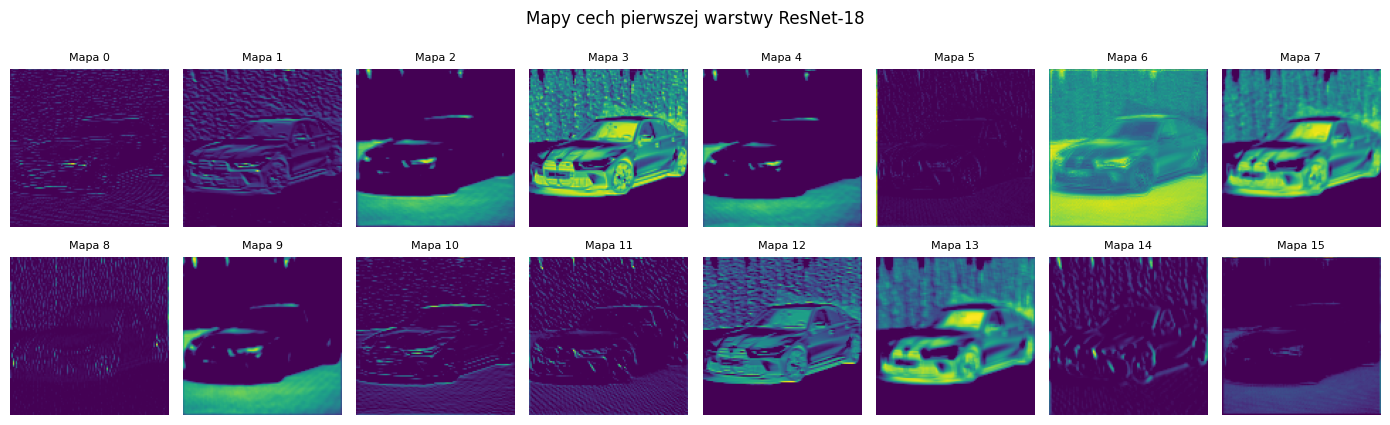

In [6]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

x = weights.transforms()(pil.convert("RGB")).unsqueeze(0).to(device)
with torch.no_grad():
    maps = torch.relu(model.conv1(x))[0].cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[i], cmap="viridis")
    ax.set_title(f"Mapa {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Mapy cech pierwszej warstwy ResNet-18")
plt.tight_layout()
plt.savefig("04_mapy_cech.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Porównanie filtrów rozmywających

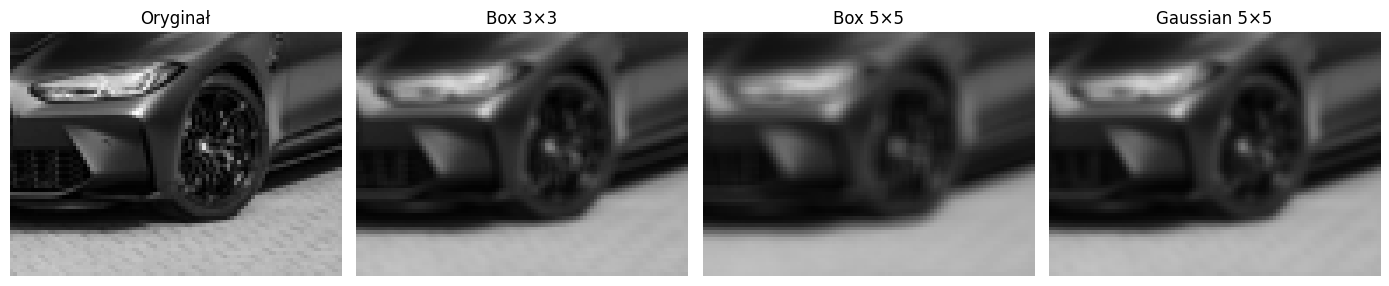

In [7]:
box3 = torch.ones(1, 1, 3, 3) / 9.0
box5 = torch.ones(1, 1, 5, 5) / 25.0
gaussian5 = kernel([
    [1, 4, 6, 4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1, 4, 6, 4, 1],
]) / 256.0

blurred = {
    "Oryginał": gray,
    "Box 3×3": F.conv2d(gray, box3, stride=1, padding=1, dilation=1),
    "Box 5×5": F.conv2d(gray, box5, stride=1, padding=2, dilation=1),
    "Gaussian 5×5": F.conv2d(gray, gaussian5, stride=1,
                              padding=2, dilation=1),
}

fragment = (slice(115, 185), slice(70, 165))
fig, axes = plt.subplots(1, len(blurred), figsize=(14, 3.5))
for ax, (name, out) in zip(axes, blurred.items()):
    ax.imshow(out[0, 0][fragment].detach(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.savefig("05_porownanie_rozmycia.png", dpi=160, bbox_inches="tight")
plt.show()